# 3.4 — Evals and tracing
**Session 3.4 · Lab**

What we'll do: grow the 15 questions into a 30-case eval set, test an LLM judge against human
labels, measure search and answers separately, and add tracing.

**What we evaluate:** the assistant from 3.2, which searches the documents and answers with citations,
and at the end an agentic RAG version, where search is a tool the model decides to use.

## What we're building

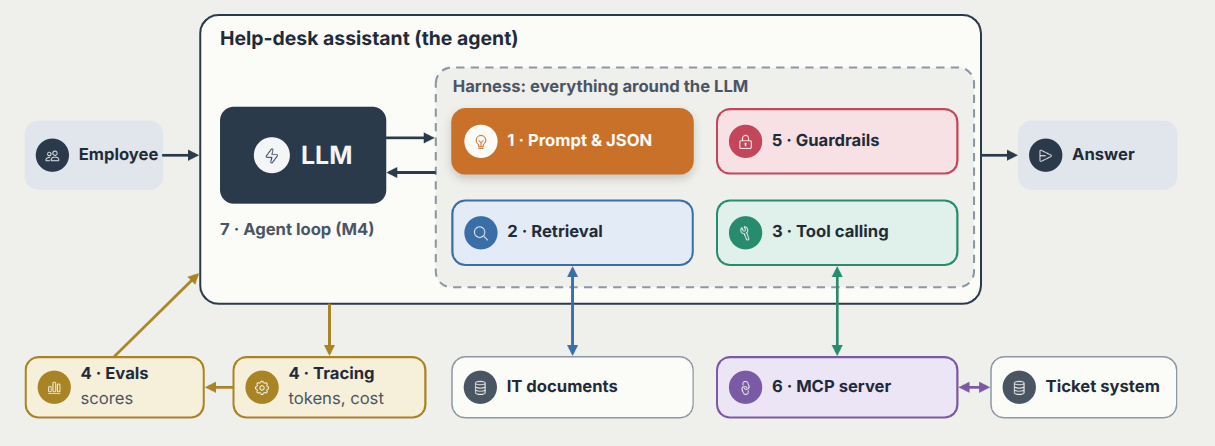

In [19]:
# @title Choose the model { display-mode: "form" }
MODEL_CHOICE = "Claude"  # @param ["Claude", "Open-weight model"]
OPEN_MODEL = "qwen3:8b"  # @param ["qwen3:8b", "qwen3:4b", "gpt-oss:20b", "llama3.1:8b"]

import importlib.util
import os
import shutil
import subprocess
import sys
import time

import requests
from IPython.display import HTML, display

OLLAMA = "http://127.0.0.1:11434"


def ollama_running():
    try:
        return requests.get(f"{OLLAMA}/api/tags", timeout=5).ok
    except requests.RequestException:
        return False


def start_ollama():
    """Install Ollama if needed, start it, and download the model."""
    if shutil.which("ollama") is None:
        subprocess.run("apt-get install -y -qq pciutils zstd > /dev/null", shell=True)
        subprocess.run("curl -fsSL https://ollama.com/install.sh | sh > /dev/null 2>&1", shell=True)
    if not ollama_running():
        settings = {"OLLAMA_HOST": "127.0.0.1:11434", "OLLAMA_CONTEXT_LENGTH": "16384", "OLLAMA_NUM_PARALLEL": "2"}
        subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL,
                         env={**os.environ, **settings})
        for _ in range(60):
            if ollama_running():
                break
            time.sleep(1)
    requests.post(f"{OLLAMA}/api/pull", json={"model": OPEN_MODEL, "stream": False}, timeout=1800).raise_for_status()


def without_cache_control(value):
    """Ollama has no prompt caching, so the caching marks are removed."""
    if isinstance(value, dict):
        return {key: without_cache_control(item) for key, item in value.items() if key != "cache_control"}
    if isinstance(value, list):
        return [without_cache_control(item) for item in value]
    return value


def report_local_model():
    """Where the kit reports a model and a cost, show the local model and $0."""
    kit_llm = sys.modules.get("helpdesk_kit.llm")
    if kit_llm is None or hasattr(kit_llm.Reply, "claude_init"):
        return
    kit_llm.cost = lambda usage, model: 0.0
    kit_llm.Reply.claude_init = kit_llm.Reply.__init__

    def local_init(reply, *args, **kwargs):
        kit_llm.Reply.claude_init(reply, *args, **kwargs)
        reply.model = OPEN_MODEL

    kit_llm.Reply.__init__ = local_init


def open_model_create(self, **request):
    """Send a request written for Claude to the open-weight model."""
    request = without_cache_control({**request, "model": OPEN_MODEL})
    request.setdefault("thinking", {"type": "disabled"})  # Thinking is slow on a T4; on only when asked for.
    report_local_model()
    return Messages.claude_create(self, **request)


if MODEL_CHOICE == "Open-weight model":
    if shutil.which("nvidia-smi") is None:
        raise RuntimeError("No GPU: choose Runtime > Change runtime type > T4 GPU, then run the notebook again.")
    start_ollama()
    if importlib.util.find_spec("anthropic") is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "anthropic"])
    from anthropic.resources.messages import Messages

    # Every connection made from here on goes to Ollama, which doesn't check the key.
    os.environ.update(ANTHROPIC_BASE_URL=OLLAMA, ANTHROPIC_API_KEY="ollama")
    if not hasattr(Messages, "claude_create"):
        Messages.claude_create = Messages.create
    Messages.create = open_model_create
    message = f"Every request goes to <b>{OPEN_MODEL}</b>."
elif os.environ.get("ANTHROPIC_BASE_URL") == OLLAMA:
    message = "Still on the open-weight model. To use Claude, restart the session and run the notebook again."
else:
    message = "Every request goes to Claude."
USING_OPEN_MODEL = os.environ.get("ANTHROPIC_BASE_URL") == OLLAMA
display(HTML(f'<div style="padding:8px 12px;border-left:4px solid #2a9d8f;background:#f4f8f7">{message}</div>'))

In [ ]:
# @title Setup: install the kit and the tracing packages, and connect to the model { display-mode: "form" }
KIT_URL = "git+https://github.com/fastbatchai/helpdesk-assistant.git"
KIT = f"helpdesk-kit[rag] @ {KIT_URL}"

import importlib, importlib.util, shutil, subprocess, sys
INSTALL = (["uv", "pip", "install", "--python", sys.executable, "-q"] if shutil.which("uv")
           else [sys.executable, "-m", "pip", "install", "-q"])
required = {"helpdesk_kit": KIT, "chromadb": KIT}
missing = {package for module, package in required.items() if importlib.util.find_spec(module) is None}
if missing:
    subprocess.check_call([*INSTALL, *missing])
    importlib.invalidate_caches()

import html

import pandas as pd
from IPython.display import HTML, display

from helpdesk_kit import tracing
from helpdesk_kit.assistant import RagAssistant
from helpdesk_kit.evals import (
    EVAL_30_PATH, EVAL_PATH, JUDGE_PATH, add_quality, load_eval_set, plot_pass_rates, run_eval, score,
)
from helpdesk_kit.llm import chat, get_client, parse_json
from helpdesk_kit.retrieval import Retriever, chunk_docs, load_kb
from helpdesk_kit.tickets import TicketStore
from helpdesk_kit.tools import tool_loop

pd.set_option("display.max_colwidth", None)
get_client()
retriever = Retriever(chunk_docs(load_kb()))
assistant = RagAssistant(retriever)
store = TicketStore()

# Display helpers, so the results read well on a shared screen.
INK, SOFT_INK, BLUE, ORANGE, AQUA, GREY = "#0b0b0b", "#52514e", "#2a78d6", "#eb6834", "#1baf7a", "#898781"
GRID = "#e1e0d9"
BOX = f"margin:8px 0;padding:10px 14px;background:#fff;border:1px solid {GRID};border-radius:6px"


def badge(text, colour):
    return (
        f'<span style="display:inline-block;margin:2px 6px 2px 0;padding:2px 8px;border-radius:10px;'
        f'background:{colour};color:#fff;font-size:12px;font-weight:600">{html.escape(str(text))}</span>'
    )


def verdict_badge(verdict):
    """pass in aqua, fail in orange."""
    return badge(verdict, AQUA if verdict == "pass" else ORANGE)


def show_card(title, body_html, colour=BLUE):
    """A card with a coloured edge: a title, then any HTML."""
    display(HTML(
        f'<div style="{BOX};border-left:3px solid {colour}">'
        f'<div style="color:{INK};font-weight:600;margin-bottom:6px">{html.escape(title)}</div>{body_html}</div>'
    ))


def rows_html(rows):
    """(label, value) rows as a small two-column table. Values are HTML."""
    body = "".join(
        f'<tr><td style="padding:4px 16px 4px 0;color:{SOFT_INK};vertical-align:top">{html.escape(str(label))}</td>'
        f'<td style="padding:4px 0;color:{INK}">{value}</td></tr>'
        for label, value in rows
    )
    return f'<table style="border-collapse:collapse">{body}</table>'


def show_table(columns, rows, headline=""):
    """A table with a header row, and an optional headline above it. Cells are HTML."""
    headline_html = (f'<div style="font-size:16px;font-weight:600;color:{INK};margin:4px 0 8px">'
                     f'{html.escape(headline)}</div>') if headline else ""
    header = "".join(
        f'<th style="padding:6px 14px 6px 0;text-align:left;color:{SOFT_INK};font-weight:600">{html.escape(name)}</th>'
        for name in columns
    )
    body = "".join(
        "<tr>" + "".join(
            f'<td style="padding:6px 14px 6px 0;vertical-align:top;color:{INK};border-top:1px solid {GRID}">{cell}</td>'
            for cell in row
        ) + "</tr>"
        for row in rows
    )
    display(HTML(f'{headline_html}<table style="border-collapse:collapse;background:#fff">'
                 f'<tr>{header}</tr>{body}</table>'))


def text_html(text, limit=None):
    """Plain text, escaped, cut to a length if asked."""
    text = str(text)
    if limit and len(text) > limit:
        text = text[:limit] + "…"
    return f'<span style="white-space:pre-wrap">{html.escape(text)}</span>'


show_card("Ready.", text_html("The assistant is loaded."))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

In [ ]:
# @title Answer caching { display-mode: "form" }
# @markdown When this is on, a request that is exactly the same as one already sent gets the saved answer
# @markdown back. Untick it (and run this step) to get fresh answers from the model.
REPLAY = True  # @param {type:"boolean"}

import hashlib
import json
import os
from contextlib import contextmanager

import anthropic
from anthropic.resources.messages import Messages

REPLAY_DIR = "/content/claude_replay" if os.path.isdir("/content") else os.path.expanduser("~/claude_replay")
os.makedirs(REPLAY_DIR, exist_ok=True)
if not hasattr(Messages, "live_create"):
    Messages.live_create = Messages.create  # The real call, kept so we can switch back.
replay_count = {"saved answers reused": 0, "new calls": 0}


def replay_create(self, **request):
    """Every call to the model comes through here: reuse a saved answer, or call the model and save the answer."""
    # The connection type and address are part of the key, so a simulated outage never gets a saved answer,
    # and a local model never gets one of Claude's.
    connection = type(getattr(getattr(self._client, "_client", None), "_transport", None)).__name__
    address = str(self._client.base_url)
    key = hashlib.sha256(json.dumps([connection, address, request], sort_keys=True, default=str).encode()).hexdigest()
    path = os.path.join(REPLAY_DIR, f"{key}.json")
    if os.path.exists(path):
        replay_count["saved answers reused"] += 1
        with open(path) as file:
            return anthropic.types.Message.model_validate_json(file.read())
    response = Messages.live_create(self, **request)
    if isinstance(response, anthropic.types.Message):  # Streamed replies aren't saved.
        with open(path, "w") as file:
            file.write(response.model_dump_json())
    replay_count["new calls"] += 1
    return response


Messages.create = replay_create if REPLAY else Messages.live_create


@contextmanager
def fresh_answers():
    """Inside this block, every request goes to the model, even with saved answers on. Used for timings."""
    current = Messages.create
    Messages.create = Messages.live_create
    try:
        yield
    finally:
        Messages.create = current


saved = len(os.listdir(REPLAY_DIR))
print(f"Saved answers {'on' if REPLAY else 'off'}. {saved} saved so far in {REPLAY_DIR}.")

Saved answers on. 204 saved so far in /content/claude_replay.


## Opening demo: walk through a trace
A trace records each step of one request. Here's one question through retrieval, and one through
a tool call; both questions are fields you can change. **Walk through:** the retrieved chunks, the full
prompt, the tool call and the tokens, then the answer.

In [ ]:
# @title Walk through a trace { display-mode: "form" }
RETRIEVAL_QUESTION = "How do I reset my password?"  # @param {type:"string"}
TOOL_QUESTION = "What's the status of ticket 1042?"  # @param {type:"string"}


def show_steps():
    """Each recorded step of the last request: time, tokens, and what it read or did."""
    for record in tracing.SPANS:
        rows = [("time", f"{record['seconds']}s"),
                ("tokens", f"{record['input_tokens']} in · {record['output_tokens']} out")]
        for key, label in (("chunks", "retrieved chunks"), ("tool", "tool"), ("arguments", "arguments"), ("result", "result")):
            if key in record:
                rows.append((label, text_html(record[key], limit=600)))
        if "prompt" in record:
            rows.append(("prompt", f'<div style="max-height:180px;overflow-y:auto;font-family:monospace;font-size:12px">'
                                   f'{text_html(record["prompt"], limit=1500)}</div>'))
        show_card(f"Step: {record['name']}", rows_html(rows))


def show_question(label, question):
    display(HTML(f'<div style="margin:14px 0 4px;font-size:16px;font-weight:600;color:{INK}">{label}: '
                 f'<span style="color:{BLUE}">"{html.escape(question)}"</span></div>'))


show_question("Through retrieval", RETRIEVAL_QUESTION)
tracing.SPANS.clear()
reply = assistant.answer_with_usage(RETRIEVAL_QUESTION)
show_steps()
show_card("The answer", text_html(reply["answer"]))

show_question("Through a tool call", TOOL_QUESTION)
tracing.SPANS.clear()
answer = tool_loop(TOOL_QUESTION, store)
show_steps()
show_card("The answer", text_html(answer))

time,0.046s
tokens,0 in · 0 out
retrieved chunks,"['password-policy-2021#1', 'password-policy-2021#0', 'password-reset-policy#1', 'account-lockout#2', 'account-lockout#1']"


time,0.002s
tokens,2228 in · 217 out
prompt,"<documents> <document source=""password-policy-2021"" title=""Password Policy"" updated=""2021-03-15""> disabled until you contact the help desk. ## How to reset your password Password resets are handled by the help desk. To request a reset: 1. Phone the help desk or email helpdesk@northgate.example from a colleague's account. 2. Give your employee number and date of birth. 3. The engineer will read you a temporary password over the phone. 4. Change the temporary password the next time you sign in. Resets are normally completed within one business day. ## Failed sign-ins After three failed attempts your account is locked. Only the help desk can unlock it, so please call during office hours. ## Compliance Compliance with this policy is checked annually. Anyone who repeatedly fails to follow it may be referred </document> <document source=""password-policy-2021"" title=""Password Policy"" updated=""2021-03-15""> # Password Policy All staff must follow the rules below to keep Northgate systems secure. ## Password rules - Passwords must be at least 8 characters long. - Passwords must include an uppercase letter, a lowercase letter, a number and a symbol. - You cannot reuse any of your last 3 passwords. - Never write your password down or share it with a colleague. ## How often you must change it All passwords expire every 90 days. You will receive an email reminder 10 days before expiry. If you do not change your password in time, your account will be disabled until you contact the help des…"


time,0.059s
tokens,0 in · 0 out


time,0.002s
tokens,722 in · 56 out


time,0.0s
tokens,0 in · 0 out
tool,lookup_ticket
arguments,"{""ticket_id"": 1042}"
result,"{""id"": 1042, ""title"": ""VPN disconnects every 10 minutes"", ""description"": ""NorthLink drops about every 10 minutes when I work from home, showing NGL-117. I am on Wi-Fi and on version 6.2. I turned off adapter power saving but it still happens. Logs are attached."", ""requester"": ""s.okafor@northgate.example"", ""category"": ""network"", ""priority"": ""P3"", ""status"": ""in_progress"", ""created_at"": ""2026-10-01T08:21:00Z""}"


time,0.001s
tokens,947 in · 161 out


## 1. Turn the 15 questions into a 30-case eval set
A good case says what "pass" means, in a sentence a reviewer could check. We add cases the set
doesn't cover yet: an edge case, a trap, or a failure we've seen. Here is what one case looks like.

In [ ]:
# @title The fields of one case { display-mode: "form" }
base_cases = load_eval_set(EVAL_PATH)
show_card(f"Starting with {len(base_cases)} cases. One of them:",
          rows_html([(field, text_html(value)) for field, value in base_cases[0].items()]))

id,q01
question,How do I reset my password?
type,in_scope
category,account_access
needs_human,False
expected_sources,['password-reset-policy']


In [ ]:
# Our new test cases. Each one says what a passing answer must say.
MY_CASES = [
    {
        "question": "How long is a guest Wi-Fi voucher valid?",
        "type": "in_scope",
        "category": "network",
        "needs_human": False,
        "expected_sources": ["guest-wifi"],
        "pass_criteria": "Says 24 hours for a standard voucher.",
    },
    {
        "question": "What's the minimum length for a password?",
        "type": "in_scope",
        "category": "account_access",
        "needs_human": False,
        "expected_sources": ["password-reset-policy"],
        "pass_criteria": "Says 14 characters. Must not say 8.",
    },
    {
        "question": "I lost my company laptop on the train this morning.",
        "type": "needs_human",
        "category": "security",
        "needs_human": True,
        "expected_sources": ["laptop-replacement-policy"],
        "pass_criteria": "Tells the user to phone extension 4357 right away so the laptop can be locked.",
    },
]

## 2. LLM-as-judge for faithfulness
Is every claim in the answer supported by the context? We can ask a model, but can we trust it?
These answers have human labels. We measure how often the judge agrees. The first 10 are clear-cut; the
last 4 are borderline, the kind people argue about: an answer that's true but incomplete, a harmless tip
the context doesn't mention, a rude reply.

In [ ]:
BORDERLINE_CASES = [
    {"id": "b1", "question": "I need to send a 40 MB file. What's the attachment limit?",
     "context": "Attachments: up to 25 MB. Share larger files with a link to a shared drive.",
     "answer": "Up to 25 MB.",
     "human_label": "fail"},  # True, but leaves out what to do with bigger files.
    {"id": "b2", "question": "How long does an account stay locked?",
     "context": "The lock lifts by itself after 30 minutes, with no action needed.",
     "answer": "30 minutes. If you're in a hurry, try restarting your laptop first.",
     "human_label": "pass"},  # The tip isn't in the context, but it's harmless.
    {"id": "b3", "question": "Can guests use NG-Staff?",
     "context": "Guests must never be connected to NG-Staff.",
     "answer": "No. And honestly, why would you even ask that?",
     "human_label": "fail"},  # Correct, but rude.
    {"id": "b4", "question": "Who approves shared drive access?",
     "context": "The data owner receives the request and approves it, normally within two business days.",
     "answer": "The data owner, usually within two business days. Ask your manager if you don't know who that is.",
     "human_label": "pass"},  # The tip isn't in the context, but it's helpful.
]

In [ ]:
# @title The answers with human labels { display-mode: "form" }
judge_cases = load_eval_set(JUDGE_PATH) + BORDERLINE_CASES
show_table(
    ["", "question", "context", "answer", "human"],
    [[case["id"], text_html(case["question"]), text_html(case["context"]), text_html(case["answer"]),
      verdict_badge(case["human_label"])] for case in judge_cases],
)

,question,context,answer,human
j01,How long does an account stay locked?,"The lock lifts by itself after 30 minutes, with no action needed.",Your account unlocks by itself after 30 minutes.,pass
j02,How long does an account stay locked?,"The lock lifts by itself after 30 minutes, with no action needed.","Your account stays locked for 24 hours, or until the help desk unlocks it.",fail
j03,How often are laptops replaced?,"Laptops are replaced on a four-year cycle, counted from the date of issue.",Every four years. IT will also give you a free docking station when it happens.,fail
j04,Can guests use NG-Staff?,Guests must never be connected to NG-Staff.,No. Guests can't use NG-Staff.,pass
j05,What is the attachment limit?,Attachments: up to 25 MB. Share larger files with a link to a shared drive.,"You can attach up to 25 MB. For anything bigger, share a link to a shared drive.",pass
j06,Who approves shared drive access?,"The data owner receives the request and approves it, normally within two business days.","Great question! Your line manager or the help desk can approve this right away, so don't worry.",fail
j07,What is the on-call number for Leeds?,"Phone extension 4357 from an internal phone, or the on-call number on the back of your badge.","I don't know the specific number for Leeds. Use extension 4357, or the number on the back of your badge.",pass
j08,How long do documents wait at the printer?,Documents wait for 48 hours and are then deleted.,Print jobs wait for two days and are then deleted.,pass
j09,Does the VPN work on my personal laptop?,NorthLink does not run on personal devices.,"Yes, as long as you install the latest version of NorthLink from Company Apps.",fail
j10,What should I do with suspicious attachments?,Press the Report Phish button in Outlook. The message is removed from your mailbox.,"Press Report Phish in Outlook, which removes the message. Our security software also scans every attachment automatically, so you're fully protected.",fail


We write the judge's instructions: what counts as a failure, and what still passes.

In [ ]:
# Our instructions for the judge.
JUDGE_INSTRUCTIONS = (
    "Check this help-desk answer against the context. Fail it if it states anything the context "
    "doesn't support, even if that claim sounds reasonable or helpful. Pass it if every claim is "
    "supported, including when it correctly says it doesn't know."
)

In [ ]:
# @title Run the judge and compare with the humans { display-mode: "form" }
def my_judge(question, context, answer):
    """Ask the model for a pass or fail verdict, with a one-sentence reason."""
    reply = chat(
        f"{JUDGE_INSTRUCTIONS}\n\n"
        f"<context>{context}</context>\n<question>{question}</question>\n<answer>{answer}</answer>\n\n"
        'Return only JSON: {"verdict": "pass" or "fail", "reason": "one sentence"}',
        max_tokens=4000,
    )
    return parse_json(reply.text)


rows = []
for case in judge_cases:
    verdict = my_judge(case["question"], case["context"], case["answer"])
    rows.append({
        "id": case["id"],
        "human": case["human_label"],
        "judge": verdict["verdict"],
        "agree": verdict["verdict"] == case["human_label"],
        "reason": verdict["reason"],
    })
judge_table = pd.DataFrame(rows)

show_table(
    ["", "human", "judge", "agree?", "the judge's reason"],
    [[row["id"], verdict_badge(row["human"]), verdict_badge(row["judge"]),
      badge("✓", AQUA) if row["agree"] else badge("✗", ORANGE), text_html(row["reason"])] for row in rows],
    headline=f"The judge agrees with the humans on {judge_table['agree'].mean():.0%} of the answers.",
)

,human,judge,agree?,the judge's reason
j01,pass,pass,✓,"The answer states the account unlocks by itself after 30 minutes, which is directly supported by the context saying the lock lifts by itself after 30 minutes."
j02,fail,fail,✓,"The answer claims a 24-hour lock and a help-desk unlock option, but the context says the lock lifts automatically after 30 minutes and mentions nothing about the help desk unlocking it."
j03,fail,fail,✓,"The four-year replacement cycle is supported, but the claim that IT will give a free docking station is not mentioned anywhere in the context."
j04,pass,pass,✓,"The answer says guests can't use NG-Staff, which matches the context stating guests must never be connected to it, and adds no unsupported claims."
j05,pass,pass,✓,"The answer restates the context directly: a 25 MB attachment limit and sharing a link to a shared drive for larger files, with no unsupported additions."
j06,fail,fail,✓,"The context says the data owner approves the request, normally within two business days, but the answer claims the line manager or help desk can approve it right away, which contradicts and is unsupported by the context."
j07,pass,pass,✓,"The answer correctly says the context gives no Leeds-specific number and only repeats the supported options, extension 4357 and the on-call number on the badge, without adding unsupported claims."
j08,pass,pass,✓,"The answer restates the context accurately, since 48 hours equals two days and the documents are then deleted, and 'print jobs' is just another name for the documents waiting at the printer in the question."
j09,fail,fail,✓,"The context says NorthLink does not run on personal devices, but the answer says yes and adds an unsupported installation instruction from Company Apps."
j10,fail,fail,✓,"The context only says that pressing Report Phish in Outlook removes the message; it says nothing about security software automatically scanning every attachment or about users being fully protected, so those claims are unsupported."


**Think about the disagreements.** Most of them come from the borderline answers: the judge checks
exactly what its instructions ask (is every claim supported?), while people also care whether the answer
is complete and polite. Change the judge's instructions to say what you care about, for example "fail an
answer that leaves out something the employee needs, or that is rude", and run the step again.

## 3. RAG evals: measure search and answer separately
A RAG answer can go wrong in two places: **search** didn't find the right document, or **the answer** was
wrong even though the document was there.

**Search** first. For each test question we know the right document, so we can check where it lands:

$$\text{recall@}k = \frac{\text{right documents in the top } k}{\text{all right documents}}
\qquad \text{precision@}k = \frac{\text{right documents in the top } k}{k}$$

$$\text{MRR} = \text{the average over all questions of } \frac{1}{\text{place of the first right document}}$$

- **recall@k:** did search find the right document at all, within the first $k$? This is the one that
  matters most for RAG: a document that isn't found can't be used.
- **precision@k:** how much of what we send is useful? Low precision means paying for passages that don't help.
- **MRR** (mean reciprocal rank): how high the right document comes. 1st place counts 1, 2nd counts $\frac{1}{2}$,
  3rd counts $\frac{1}{3}$; 1.0 means always first.


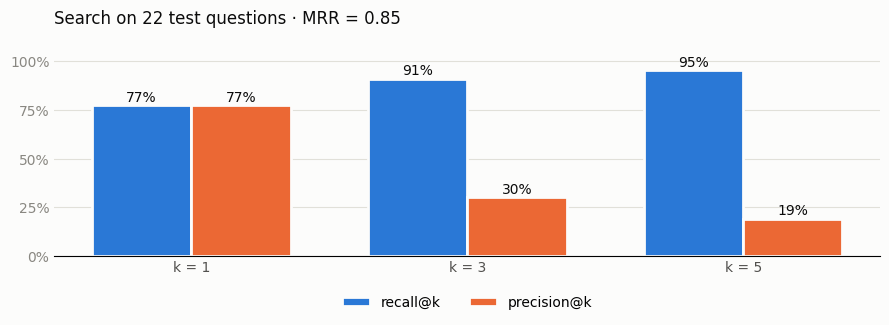

question,right document,where search put it,1 / place
How do I reset my password?,password-reset-policy,#2,0.50
What hours is the IT help desk open?,help-desk-policy,#1,1.00
How soon should I expect a first response to a P2 ticket?,help-desk-policy,#3,0.33
My VPN shows error NGL-809. What does it mean?,vpn-troubleshooting,#1,1.00
How often does my laptop get replaced?,laptop-replacement-policy,#1,1.00
How many failed sign-ins before my account locks?,account-lockout,#1,1.00
How often do I have to change my password?,password-reset-policy,#2,0.50
I got an email that looks like phishing but I didn't click anything. What should I do?,phishing-reporting,#1,1.00
I clicked a link in a strange email and typed in my password. What now?,phishing-reporting,#1,1.00
The whole Hamburg office has lost its network and the warehouse can't ship. Help!,incident-severity-levels,#7,0.14


In [ ]:
# @title Measure search: recall@k, precision@k and MRR { display-mode: "form" }
import matplotlib.pyplot as plt

search_cases = [case for case in load_eval_set(EVAL_30_PATH) if case.get("expected_sources")]
KS = (1, 3, 5)


def top_documents(question, k):
    """The first k different documents search returns for a question."""
    documents = list(dict.fromkeys(chunk.doc_id for chunk in retriever.hybrid_search(question, k=4 * k)))
    return documents[:k]


rows, recall, precision, reciprocal_ranks = [], {k: [] for k in KS}, {k: [] for k in KS}, []
for case in search_cases:
    right = set(case["expected_sources"])
    ranked = top_documents(case["question"], 10)
    place = next((number for number, doc in enumerate(ranked, start=1) if doc in right), None)
    reciprocal_ranks.append(1 / place if place else 0)
    for k in KS:
        found = len(right & set(ranked[:k]))
        recall[k].append(found / len(right))
        precision[k].append(found / k)
    rows.append([text_html(case["question"]), text_html(", ".join(case["expected_sources"])),
                 badge(f"#{place}", AQUA if place == 1 else BLUE) if place else badge("not in top 10", ORANGE),
                 f"{1 / place:.2f}" if place else "0"])

mean = lambda values: sum(values) / len(values)
figure, ax = plt.subplots(figsize=(9, 3.4), facecolor="#fcfcfb")
for number, (name, values, colour) in enumerate((("recall@k", recall, BLUE), ("precision@k", precision, ORANGE))):
    positions = [index + (number - 0.5) * 0.36 for index in range(len(KS))]
    heights = [mean(values[k]) for k in KS]
    ax.bar(positions, heights, width=0.36, color=colour, label=name, edgecolor="#fcfcfb", linewidth=2)
    for position, height in zip(positions, heights):
        ax.text(position, height + 0.02, f"{height:.0%}", ha="center", color=INK, fontsize=10)
ax.set_xticks(range(len(KS)), [f"k = {k}" for k in KS], color=SOFT_INK)
ax.set_ylim(0, 1.15)
ax.set_yticks([0, 0.25, 0.5, 0.75, 1], ["0%", "25%", "50%", "75%", "100%"], color=GREY)
ax.set_title(f"Search on {len(search_cases)} test questions · MRR = {mean(reciprocal_ranks):.2f}", loc="left", color=INK)
ax.set_facecolor("#fcfcfb")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(length=0)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
figure.tight_layout()
plt.show()

show_table(["question", "right document", "where search put it", "1 / place"], rows,
           headline="Question by question")

Recall rising with $k$ while precision falls: sending more passages finds more right documents,
but more of what we send is noise. Each question here has one right document, so precision@5 can't go
above 20%.

## 4. Add tracing and run the suite
We run the 30 cases through the assistant: search, then an answer with citations (fixed RAG). Section 5
runs the same cases with agentic RAG.

Every step the assistant takes is recorded and sent to **Phoenix**, an open-source tracing tool that runs
inside this Colab, with no account.

In [ ]:
# @title Start Phoenix { display-mode: "form" }
subprocess.check_call([*INSTALL, "arize-phoenix", "arize-phoenix-otel"])
importlib.invalidate_caches()
import contextlib, io, logging, re, warnings

# Phoenix prints a lot while it starts (database warnings, setup details): keep the screen clean.
warnings.filterwarnings("ignore")
logging.getLogger("phoenix").setLevel(logging.ERROR)
with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
    phoenix_url = tracing.setup_phoenix()  # Phoenix runs inside this Colab, on port 6006.
found = re.search(r"[-:](\d{4,5})(?=[-/]|$)", phoenix_url.rstrip("/"))
port = int(found.group(1)) if found else 6006
show_card("Tracing to Phoenix",
          text_html("Click the link below to open Phoenix in a new tab. Each question is one trace; "
                    "click it to see its steps, their time and their tokens."))
try:
    from google.colab import output as colab_output

    # "localhost" would point at your own computer; Colab forwards the port to your browser instead.
    try:
        colab_output.serve_kernel_port_as_window(port, anchor_text="Open Phoenix")
    except TypeError:  # Older Colab: the same link, with the address as its text.
        colab_output.serve_kernel_port_as_window(port)
except ImportError:  # Not on Colab: the local address works as it is.
    display(HTML(f'<a href="{phoenix_url}" target="_blank">Open Phoenix</a>'))

In [ ]:
# @title Run the 30 cases { display-mode: "form" }
eval_set = load_eval_set(EVAL_30_PATH)  # The 15 questions, our new cases, and more: 30 in all.
tracing.SPANS.clear()
results = run_eval(assistant.answer_with_usage, eval_set)
results = add_quality(score(results))
tracing.flush()

plot_pass_rates({"assistant": results}, "How often the assistant's labels match the eval set")

sources = [result["sources_ok"] for result in results if result["sources_ok"] is not None]
show_card("The suite in numbers", rows_html([
    ("cases", len(results)),
    ("found the expected documents", f"{sum(sources)}/{len(sources)}" if sources else "not measured"),
    ("meet their pass criteria (judge)", f"{sum(r['quality_ok'] for r in results)}/{len(results)}"),
]))

### Find the slowest and most expensive step


In [ ]:
# @title Time and tokens per step { display-mode: "form" }
steps = tracing.span_table()
show_table(
    ["step", "calls", "total time", "time per call", "total tokens"],
    [[html.escape(name), row["calls"], f"{row['total_seconds']:.1f}s", f"{row['avg_seconds']:.2f}s",
      f"{int(row['total_tokens']):,}"] for name, row in steps.iterrows()],
    headline="Every step of the run, slowest first",
)

slowest = sorted(results, key=lambda result: result["seconds"], reverse=True)[:3]
show_table(
    ["", "question", "time", "tokens"],
    [[result["id"], text_html(result["question"]), f"{result['seconds']:.1f}s", result.get("tokens", "")]
     for result in slowest],
    headline="The three slowest questions",
)

In [ ]:
# @title The answers that failed their pass criteria { display-mode: "form" }
failures = [result for result in results if not result["quality_ok"]]
if not failures:
    show_card("No failures.", text_html("Every answer meets its pass criteria."), colour=AQUA)
for result in failures:
    show_card(f"{result['id']}: {result['question']}", rows_html([
        ("answer", text_html(result.get("answer", ""))),
        ("judge", verdict_badge("fail") + text_html(result["quality_reason"])),
    ]), colour=ORANGE)

## 5. Agentic RAG on the same 30 cases
So far, search runs once, before the model, with the employee's exact words: **fixed RAG**.

With **agentic RAG**, search becomes a **tool**: an action we describe to the model, with its name and what it
needs. The model decides **whether** to search, **with which
words**, and whether to **search again** before it answers.


In [ ]:
from pydantic import ValidationError

from helpdesk_kit.assistant import CITED_EXAMPLES, SYSTEM_PROMPT, CitedReply, build_prompt, format_context
from helpdesk_kit.llm import Meter, extract_json

SEARCH_TOOL = {
    "name": "search_documents",
    "description": (
        "Search Northgate's IT documents (policies, how-tos, error codes). Write the query in your own words, "
        "using the terms an IT document would use. If the results don't answer the question, search again."
    ),
    "input_schema": {"type": "object", "properties": {"query": {"type": "string"}}, "required": ["query"]},
}
AGENTIC_RULES = (
    "Before you answer an IT question, search the documents with the search_documents tool, in your own words. "
    "Search again with different words if the results don't answer it. Answer only from what you found. "
    "Cite the source id of every document you used in `sources`. If the documents don't contain the answer, "
    'say "I don\'t know" and leave `sources` empty.'
)
AGENTIC_PROMPT = build_prompt(f"{SYSTEM_PROMPT}\n\n{AGENTIC_RULES}", CITED_EXAMPLES, CitedReply)
print(AGENTIC_PROMPT)

In [ ]:
# @title Run the 30 cases with agentic RAG { display-mode: "form" }
def run_searches(requests):
    """Run each search the model asked for, and return the results to send back."""
    results = []
    for request in requests:
        query = request.input.get("query")
        if not query:
            results.append({"type": "tool_result", "tool_use_id": request.id, "is_error": True,
                            "content": "No query given: say what to search for."})
            continue
        with tracing.span("search", query=query) as step:
            passages = retriever.hybrid_search(query, k=5)
            step.set(chunks=[chunk.id for chunk in passages])
        results.append({"type": "tool_result", "tool_use_id": request.id, "content": format_context(passages)})
    return results


def model_step(messages):
    """One call to the model, with the search tool, recorded as a step."""
    with tracing.span("llm", prompt=str(messages[-1]["content"])) as step:
        reply = chat(messages, system=AGENTIC_PROMPT, tools=[SEARCH_TOOL], max_tokens=4000)
        step.add_usage(reply)
        step.set(completion=reply.text)
    return reply


def agentic_answer(question, max_steps=5, max_retries=2):
    """Agentic RAG: the model searches as often as it wants, then answers in the same JSON format."""
    meter, searches = Meter(), []
    messages = [{"role": "user", "content": question}]
    with tracing.span("agentic assistant", question=question) as whole:
        for step_number in range(1, max_steps + 1):
            reply = model_step(messages)
            meter.add(reply)
            requests = [block for block in reply.raw.content if block.type == "tool_use"]
            if not requests or step_number == max_steps:
                break
            searches += [request.input["query"] for request in requests if request.input.get("query")]
            results = run_searches(requests)
            if step_number == max_steps - 1:
                results[-1]["content"] += "\n\nThat was the last search: answer next, in the JSON format."
            messages += [{"role": "assistant", "content": reply.raw.content}, {"role": "user", "content": results}]

        # Like fixed RAG: an empty reply, or one not in the JSON format, gets another chance.
        for retry in range(max_retries + 1):
            try:
                answer = CitedReply.model_validate_json(extract_json(reply.text)).model_dump()
                break
            except ValidationError as error:
                if retry == max_retries:  # Counted as wrong on every label, and shown in the table.
                    answer = {"answer": reply.text, "category": None, "needs_human": None, "sources": [],
                              "unreadable": True}
                    break
                if reply.text.strip():
                    messages.append({"role": "assistant", "content": reply.text})
                    problem = f"That reply failed validation:\n{error}"
                elif any(block.type == "tool_use" for block in reply.raw.content):
                    problem = "No more searches."
                else:
                    problem = "Your reply was empty."
                messages.append({"role": "user", "content": f"{problem}\n\nAnswer now, in the JSON format only."})
                reply = model_step(messages)
                meter.add(reply)
        whole.set(answer=answer["answer"])
    return {**answer, "tokens": meter.total_tokens, "cost": meter.cost, "steps": meter.calls,
            "searches": len(searches), "search_words": searches}


cases_for_both = eval_set if "eval_set" in globals() else load_eval_set(EVAL_30_PATH)
if "results" not in globals():
    results = add_quality(score(run_eval(assistant.answer_with_usage, cases_for_both)))
agentic_results = add_quality(score(run_eval(agentic_answer, cases_for_both)))
tracing.flush()

plot_pass_rates({"fixed RAG": results, "agentic RAG": agentic_results}, "Fixed RAG vs agentic RAG")


def share(rows, key):
    checked = [row[key] for row in rows if row.get(key) is not None]
    return f"{sum(checked) / len(checked):.0%}" if checked else "n/a"


def average(rows, key, default=0):
    return sum(row.get(key, default) for row in rows) / len(rows)


def count(rows, key):
    return str(sum(bool(row.get(key)) for row in rows))


def cost_per_question(rows):
    """The average over the questions that got an answer; the errors row says how many didn't."""
    costs = [row["cost"] for row in rows if row.get("cost") is not None]
    return f"${sum(costs) / len(costs):.5f}" if costs else "n/a"


show_table(
    ["", "fixed RAG", "agentic RAG"],
    [
        ["meet their pass criteria (the judge)", share(results, "quality_ok"), share(agentic_results, "quality_ok")],
        ["cite the right documents", share(results, "sources_ok"), share(agentic_results, "sources_ok")],
        ["right category", share(results, "category_ok"), share(agentic_results, "category_ok")],
        ["replies not in the JSON format", count(results, "unreadable"), count(agentic_results, "unreadable")],
        ["errors", count(results, "error"), count(agentic_results, "error")],
        ["searches per question", "1.0", f"{average(agentic_results, 'searches'):.1f}"],
        ["questions with no search", "0", str(sum(row.get("searches") == 0 for row in agentic_results))],
        ["calls to the model per question", f"{average(results, 'steps', 1):.1f}", f"{average(agentic_results, 'steps', 1):.1f}"],
        ["tokens per question", f"{average(results, 'tokens'):,.0f}", f"{average(agentic_results, 'tokens'):,.0f}"],
        ["cost per question", cost_per_question(results), cost_per_question(agentic_results)],
        ["seconds per question", f"{average(results, 'seconds'):.1f}", f"{average(agentic_results, 'seconds'):.1f}"],
    ],
    headline="The same 30 cases, two ways",
)